In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)




In [3]:
data_path = Path("data/Online Retail.xlsx")
df = pd.read_excel(data_path)

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice    

In [6]:
df_clean = df.copy()

In [7]:
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df_clean = df_clean.dropna(subset=["Description"])

In [9]:
df_clean["Description"] = df_clean["Description"].astype(str).str.strip()
df_clean = df_clean[df_clean["Description"] != ""]

In [10]:
df_clean.shape

(540455, 8)

In [11]:
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str).str.strip()
cancelled = df_clean["InvoiceNo"].str.upper().str.startswith("C")

print("Cancelled invoice rows:", cancelled.sum())

df_clean = df_clean[~cancelled]

print("Shape after removing cancellations:", df_clean.shape)


Cancelled invoice rows: 9288
Shape after removing cancellations: (531167, 8)


In [12]:
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)


df_clean = df_clean.dropna(
    subset=["Quantity", "UnitPrice"]
)

df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

df_clean = df_clean.drop_duplicates()

print("Shape after cleaning:", df_clean.shape)
print("Remaining missing values:")
print(df_clean.isnull().sum())


Shape after cleaning: (524878, 8)
Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64


In [13]:

print("DATA CLEANING SUMMARY")
print("-" * 35)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print(
    "Unique invoices:",
    df_clean["InvoiceNo"].nunique()
)

print(
    "Unique products:",
    df_clean["Description"].nunique()
)


DATA CLEANING SUMMARY
-----------------------------------
Original rows: 541909
Cleaned rows: 524878
Rows removed: 17031
Unique invoices: 19960
Unique products: 4015


In [14]:
first_invoice = df_clean["InvoiceNo"].iloc[0]

df_clean[
    df_clean["InvoiceNo"] == first_invoice
][["InvoiceNo", "Description", "Quantity"]]


,InvoiceNo,Description,Quantity
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6
1,536365,WHITE METAL LANTERN,6
2,536365,CREAM CUPID HEARTS COAT HANGER,8
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6
5,536365,SET 7 BABUSHKA NESTING BOXES,2
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6


In [15]:

basket_data = (
    df_clean.groupby("InvoiceNo")["Description"]
    .apply(lambda products: sorted(set(products)))
)

transactions = basket_data.tolist()

print("Total transactions:", len(transactions))
print("\nFirst 5 transactions:")

for transaction in transactions[:5]:
    print(transaction)


Total transactions: 19960

First 5 transactions:
['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN']
['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK']
['ASSORTED COLOUR BIRD ORNAMENT', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'DOORMAT NEW ENGLAND', 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'HOME BUILDING BLOCK WORD', 'IVORY KNITTED MUG COSY', 'LOVE BUILDING BLOCK WORD', "POPPY'S PLAYHOUSE BEDROOM", "POPPY'S PLAYHOUSE KITCHEN", 'RECIPE BOX WITH METAL HEART']
['BLUE COAT RACK PARIS FASHION', 'JAM MAKING SET WITH JARS', 'RED COAT RACK PARIS FASHION', 'YELLOW COAT RACK PARIS FASHION']
['BATH BUILDING BLOCK WORD']


In [16]:
transactions = [
    basket for basket in transactions
    if len(basket) >= 2
]

print("Transactions with at least 2 products:", len(transactions))


Transactions with at least 2 products: 18319


In [17]:
encoder = TransactionEncoder()

encoded_array = encoder.fit(transactions).transform(transactions)

basket_matrix = pd.DataFrame(
    encoded_array,
    columns=encoder.columns_
)

basket_matrix.iloc[:5, :10]


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False


In [18]:

print("Basket matrix shape:", basket_matrix.shape)

print("\nTotal transactions:", basket_matrix.shape[0])

print("Unique products:", basket_matrix.shape[1])

print("\nData types:")
print(basket_matrix.dtypes.value_counts())

print("\nProducts purchased in first transaction:")
print(basket_matrix.columns[basket_matrix.iloc[0]].tolist())


Basket matrix shape: (18319, 4004)

Total transactions: 18319
Unique products: 4004

Data types:
bool    4004
Name: count, dtype: int64

Products purchased in first transaction:
['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN']


In [19]:

frequent_itemsets = apriori(
    basket_matrix,
    min_support=0.02,
    use_colnames=True,
    low_memory=True
)

frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

print("Total frequent itemsets:", len(frequent_itemsets))

frequent_itemsets.head(10)


Total frequent itemsets: 458


,support,itemsets
325,0.122114,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
125,0.113270,frozenset({JUMBO BAG RED RETROSPOT})
235,0.107320,frozenset({REGENCY CAKESTAND 3 TIER})
189,0.091162,frozenset({PARTY BUNTING})
152,0.085321,frozenset({LUNCH BAG RED RETROSPOT})
18,0.079317,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
262,0.075113,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
179,0.072056,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
145,0.069382,frozenset({LUNCH BAG BLACK SKULL.})
165,0.068126,frozenset({NATURAL SLATE HEART CHALKBOARD})


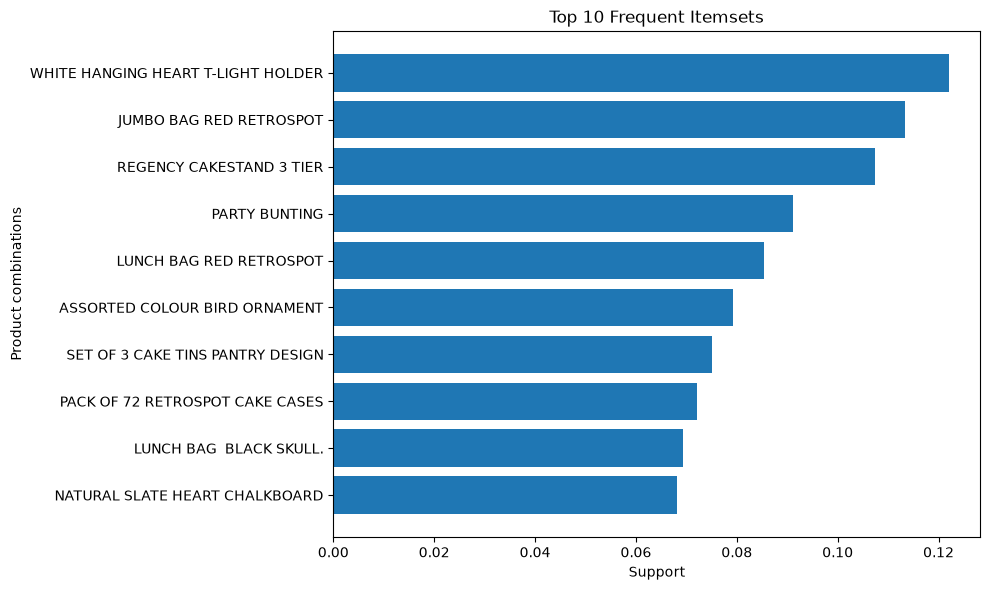

In [20]:
top_itemsets = frequent_itemsets.head(10).copy()

top_itemsets["products"] = top_itemsets["itemsets"].apply(
    lambda items: ", ".join(sorted(items))
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_itemsets["products"][::-1],
    top_itemsets["support"][::-1]
)

plt.xlabel("Support")
plt.ylabel("Product combinations")
plt.title("Top 10 Frequent Itemsets")

plt.tight_layout()
plt.show()


In [21]:

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.30
)

rules = rules.sort_values(
    by="lift",
    ascending=False
)

print("Total association rules:", len(rules))

rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(10)


Total association rules: 206


,antecedents,consequents,support,confidence,lift
178,frozenset({WOODEN HEART CHRISTMAS SCANDINAVIAN}),frozenset({WOODEN STAR CHRISTMAS SCANDINAVIAN}),0.021180,0.721190,25.854153
177,frozenset({WOODEN STAR CHRISTMAS SCANDINAVIAN}),frozenset({WOODEN HEART CHRISTMAS SCANDINAVIAN}),0.021180,0.759295,25.854153
33,"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.029532,0.705346,17.001611
38,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",0.029532,0.711842,17.001611
36,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.029532,0.534057,16.360192
35,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.029532,0.904682,16.360192
12,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.034500,0.623889,15.038198
13,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.034500,0.831579,15.038198
37,frozenset({ROSES REGENCY TEACUP AND SAUCER}),"frozenset({GREEN REGENCY TEACUP AND SAUCER, PI...",0.029532,0.509416,14.765815
34,"frozenset({GREEN REGENCY TEACUP AND SAUCER, PI...",frozenset({ROSES REGENCY TEACUP AND SAUCER}),0.029532,0.856013,14.765815


In [22]:
rules["antecedents"] = rules["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules["consequents"] = rules["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(10)


,antecedents,consequents,support,confidence,lift
178,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.021180,0.721190,25.854153
177,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.021180,0.759295,25.854153
33,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.029532,0.705346,17.001611
38,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.029532,0.711842,17.001611
36,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.029532,0.534057,16.360192
35,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.029532,0.904682,16.360192
12,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.034500,0.623889,15.038198
13,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.034500,0.831579,15.038198
37,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.029532,0.509416,14.765815
34,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.029532,0.856013,14.765815


In [23]:
rules_display = rules.copy()

rules_display["antecedents"] = rules_display["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)
rules_display["consequents"] = rules_display["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules_display[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(10)

,antecedents,consequents,support,confidence,lift
178,", , , A, A, A, A, A, C, C, D, D, E, E, H, H...",", , , A, A, A, A, A, C, C, D, D, E, H, I, I...",0.021180,0.721190,25.854153
177,", , , A, A, A, A, A, C, C, D, D, E, H, I, I...",", , , A, A, A, A, A, C, C, D, D, E, E, H, H...",0.021180,0.759295,25.854153
33,", , , , , , , , , ,, A, A, A, A, A, A...",", , , , A, A, A, C, C, C, D, E, E, E, E, G...",0.029532,0.705346,17.001611
38,", , , , A, A, A, C, C, C, D, E, E, E, E, G...",", , , , , , , , , ,, A, A, A, A, A, A...",0.029532,0.711842,17.001611
36,", , , , A, A, A, C, C, C, D, E, E, E, E, E...",", , , , , , , , , ,, A, A, A, A, A, A...",0.029532,0.534057,16.360192
35,", , , , , , , , , ,, A, A, A, A, A, A...",", , , , A, A, A, C, C, C, D, E, E, E, E, E...",0.029532,0.904682,16.360192
12,", , , , A, A, A, C, C, C, D, E, E, E, E, E...",", , , , A, A, A, C, C, C, D, E, E, E, E, G...",0.034500,0.623889,15.038198
13,", , , , A, A, A, C, C, C, D, E, E, E, E, G...",", , , , A, A, A, C, C, C, D, E, E, E, E, E...",0.034500,0.831579,15.038198
37,", , , , A, A, A, C, C, C, D, E, E, E, E, E...",", , , , , , , , , ,, A, A, A, A, A, A...",0.029532,0.509416,14.765815
34,", , , , , , , , , ,, A, A, A, A, A, A...",", , , , A, A, A, C, C, C, D, E, E, E, E, E...",0.029532,0.856013,14.765815


In [27]:

# Create cross-selling recommendations

recommendations = rules[
    (rules["lift"] > 1) &
    (rules["confidence"] >= 0.30)
].copy()

recommendations["Buy This"] = recommendations["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)

recommendations["Recommend This"] = recommendations["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

recommendations = recommendations.sort_values(
    ["lift", "confidence", "support"],
    ascending=False
)

recommendations[
    ["Buy This", "Recommend This", "support", "confidence", "lift"]
].head(10)


,Buy This,Recommend This,support,confidence,lift
177,", , , A, A, A, A, A, C, C, D, D, E, H, I, I...",", , , A, A, A, A, A, C, C, D, D, E, E, H, H...",0.021180,0.759295,25.854153
178,", , , A, A, A, A, A, C, C, D, D, E, E, H, H...",", , , A, A, A, A, A, C, C, D, D, E, H, I, I...",0.021180,0.721190,25.854153
33,", , , , , , , , , ,, A, A, A, A, A, A...",", , , , A, A, A, C, C, C, D, E, E, E, E, G...",0.029532,0.705346,17.001611
38,", , , , A, A, A, C, C, C, D, E, E, E, E, G...",", , , , , , , , , ,, A, A, A, A, A, A...",0.029532,0.711842,17.001611
35,", , , , , , , , , ,, A, A, A, A, A, A...",", , , , A, A, A, C, C, C, D, E, E, E, E, E...",0.029532,0.904682,16.360192
36,", , , , A, A, A, C, C, C, D, E, E, E, E, E...",", , , , , , , , , ,, A, A, A, A, A, A...",0.029532,0.534057,16.360192
12,", , , , A, A, A, C, C, C, D, E, E, E, E, E...",", , , , A, A, A, C, C, C, D, E, E, E, E, G...",0.034500,0.623889,15.038198
13,", , , , A, A, A, C, C, C, D, E, E, E, E, G...",", , , , A, A, A, C, C, C, D, E, E, E, E, E...",0.034500,0.831579,15.038198
34,", , , , , , , , , ,, A, A, A, A, A, A...",", , , , A, A, A, C, C, C, D, E, E, E, E, E...",0.029532,0.856013,14.765815
37,", , , , A, A, A, C, C, C, D, E, E, E, E, E...",", , , , , , , , , ,, A, A, A, A, A, A...",0.029532,0.509416,14.765815


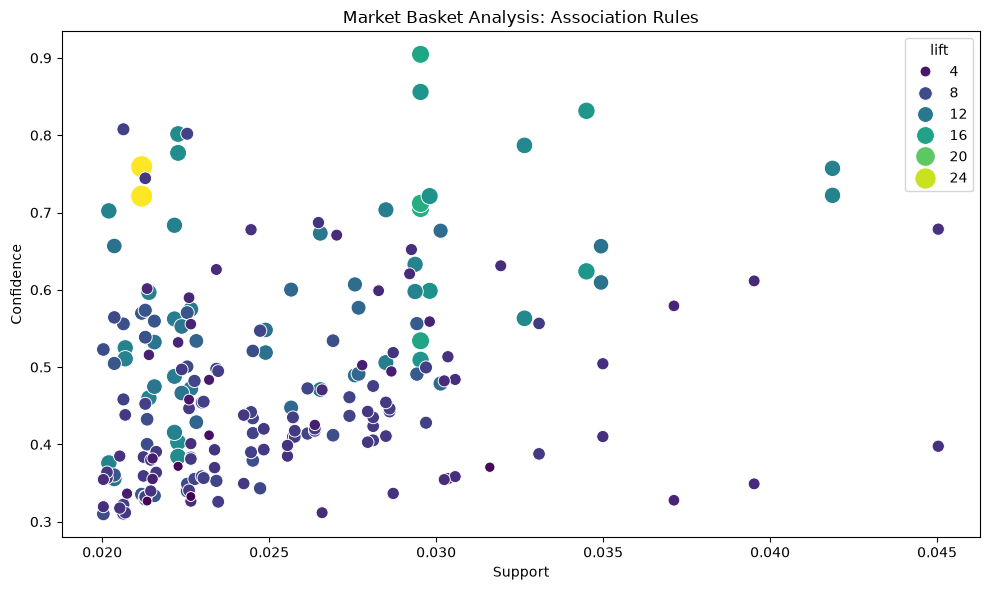

In [24]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rules,
    x="support",
    y="confidence",
    hue="lift",
    size="lift",
    sizes=(50, 250),
    palette="viridis"
)

plt.title("Market Basket Analysis: Association Rules")
plt.xlabel("Support")
plt.ylabel("Confidence")

plt.tight_layout()
plt.show()


In [28]:



recommendations[
    ["Buy This", "Recommend This", "support", "confidence", "lift"]
].to_csv("cross_selling_recommendations.csv", index=False)

print("Recommendations saved successfully!")


Recommendations saved successfully!
